In [12]:
with open("./eng-est/est.txt", "r", encoding="utf-8") as f:
    data = f.readlines()

source_target = [line.strip().split("\t")[:2] for line in data]
source_sentences, target_sentences = zip(*source_target)

In [13]:
def tokenize(text):
    return text.lower().split()

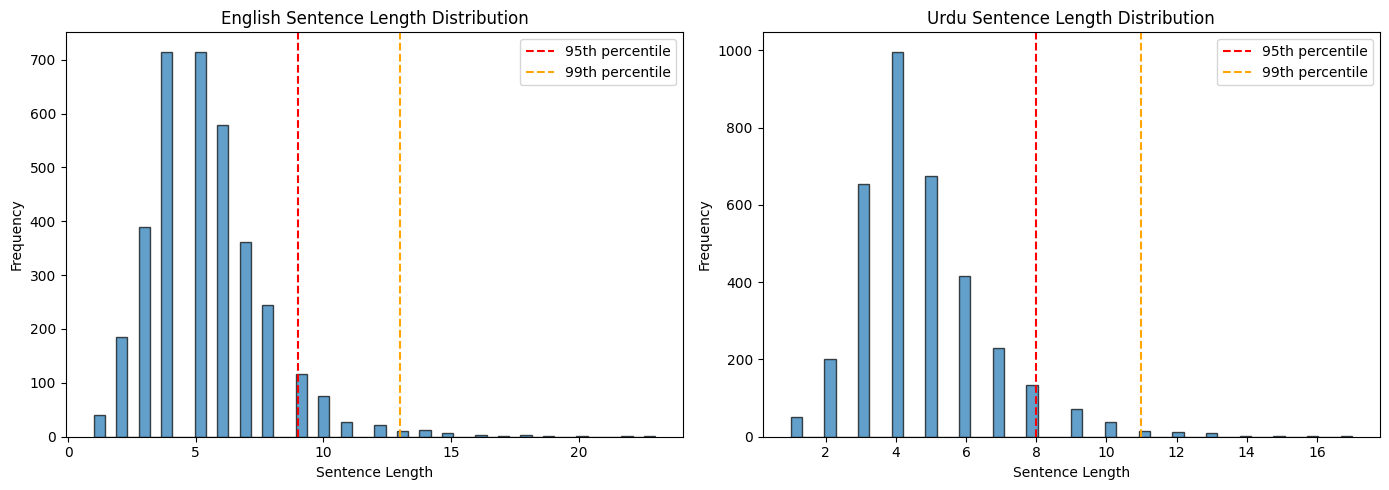

Source Sentence Lengths:
  Mean: 5.40
  Median: 5.00
  Max: 23
  95th percentile: 9
  99th percentile: 13

Target Sentence Lengths:
  Mean: 4.71
  Median: 4.00
  Max: 17
  95th percentile: 8
  99th percentile: 11


In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Analyze sentence lengths
source_lengths = [len(tokenize(s)) for s in source_sentences]
target_lengths = [len(tokenize(s)) for s in target_sentences]

# Plot distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(source_lengths, bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(np.percentile(source_lengths, 95), color='red', linestyle='--', label='95th percentile')
axes[0].axvline(np.percentile(source_lengths, 99), color='orange', linestyle='--', label='99th percentile')
axes[0].set_xlabel('Sentence Length')
axes[0].set_ylabel('Frequency')
axes[0].set_title('English Sentence Length Distribution')
axes[0].legend()

axes[1].hist(target_lengths, bins=50, edgecolor='black', alpha=0.7)
axes[1].axvline(np.percentile(target_lengths, 95), color='red', linestyle='--', label='95th percentile')
axes[1].axvline(np.percentile(target_lengths, 99), color='orange', linestyle='--', label='99th percentile')
axes[1].set_xlabel('Sentence Length')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Urdu Sentence Length Distribution')
axes[1].legend()

plt.tight_layout()
plt.show()

# Print statistics
print("Source Sentence Lengths:")
print(f"  Mean: {np.mean(source_lengths):.2f}")
print(f"  Median: {np.median(source_lengths):.2f}")
print(f"  Max: {np.max(source_lengths)}")
print(f"  95th percentile: {np.percentile(source_lengths, 95):.0f}")
print(f"  99th percentile: {np.percentile(source_lengths, 99):.0f}")

print("\nTarget Sentence Lengths:")
print(f"  Mean: {np.mean(target_lengths):.2f}")
print(f"  Median: {np.median(target_lengths):.2f}")
print(f"  Max: {np.max(target_lengths)}")
print(f"  95th percentile: {np.percentile(target_lengths, 95):.0f}")
print(f"  99th percentile: {np.percentile(target_lengths, 99):.0f}")

In [15]:
def calculate_coverage(lengths, max_length):
    """Calculate what percentage of sentences fit within max_length"""
    covered = sum(1 for length in lengths if length <= max_length)
    return (covered / len(lengths)) * 100


# Test different sequence lengths
test_lengths = [10, 15, 20, 25, 30, 40, 50]

print("Coverage Analysis:")
print(
    f"{'Max Length':<12} {'Source Coverage':<18} {'Target Coverage':<18} {'Avg Coverage'}"
)
print("-" * 70)

for max_len in test_lengths:
    source_cov = calculate_coverage(source_lengths, max_len)
    target_cov = calculate_coverage(target_lengths, max_len)
    avg_cov = (source_cov + target_cov) / 2
    print(
        f"{max_len:<12} {source_cov:>6.2f}%{' ' * 10} {target_cov:>6.2f}%{' ' * 10} {avg_cov:>6.2f}%"
    )

Coverage Analysis:
Max Length   Source Coverage    Target Coverage    Avg Coverage
----------------------------------------------------------------------
10            97.38%            98.75%            98.06%
15            99.63%            99.91%            99.77%
20            99.94%           100.00%            99.97%
25           100.00%           100.00%           100.00%
30           100.00%           100.00%           100.00%
40           100.00%           100.00%           100.00%
50           100.00%           100.00%           100.00%


In [16]:
# Calculate recommended max length
def get_recommended_max_length(lengths, coverage=0.95):
    """Get max length that covers specified percentage of data"""
    return int(np.percentile(lengths, coverage * 100))


# Get recommendations
source_max = get_recommended_max_length(source_lengths, coverage=0.95)
target_max = get_recommended_max_length(target_lengths, coverage=0.95)

# Take the maximum of both (to accommodate both languages)
recommended_max_length = max(source_max, target_max)

print(f"\nRecommended sequence length (95% coverage): {recommended_max_length}")
print(f"Source max needed: {source_max}")
print(f"Target max needed: {target_max}")

# Add buffer for special tokens (<SOS>, <EOS>)
final_max_length = recommended_max_length + 2
print(f"\nFinal recommended max_length (with buffer): {final_max_length}")


Recommended sequence length (95% coverage): 9
Source max needed: 9
Target max needed: 8

Final recommended max_length (with buffer): 11
